## Problema - Organización y búsqueda de productos en una tienda

**Instrucción:** completa esta plantilla con tu diseño y desarrollo. Evita incluir soluciones generadas automáticamente.

En este desarrollo se administra un conjunto de tareas de un centro de cómputo. Cada tarea tiene código, nombre y prioridad. Se utiliza un Max-Heap representado con un arreglo para que la tarea con mayor prioridad sea atendida primero.


In [1]:
# @title Ingrese datos
nombre_estudiante = "" # @param {"type":"string"}
carnet = None # @param {"type":"integer"}


## 1) Descripción del problema **[1 pts]**

Un centro de cómputo recibe varias tareas que deben ser procesadas por sus servidores. Cada tarea tiene un código, un nombre y un número de prioridad.

Se necesita organizar las tareas para que siempre se pueda consultar y procesar primero la que tenga la prioridad más alta. Para esto se utiliza un Max-Heap implementado con un arreglo. También se necesita poder insertar nuevas tareas y ordenar las prioridades con HeapSort.


## 2) Requerimientos **[2 pts]**

**Requerimientos funcionales**

- Registrar las tareas con su código, nombre y prioridad.
- Mostrar las prioridades en el orden en que fueron ingresadas.
- Construir un Max-Heap usando un arreglo.
- Consultar la tarea de mayor prioridad sin eliminarla.
- Extraer la tarea de mayor prioridad y reorganizar el Heap.
- Insertar una tarea nueva conservando la propiedad del Max-Heap.
- Ordenar las prioridades de menor a mayor con HeapSort.

**Requerimientos no funcionales**

- El programa debe estar desarrollado en Python.
- El Heap debe representarse con una lista, sin nodos ni punteros.
- Las operaciones del Heap deben estar implementadas manualmente.
- No se debe utilizar heapq, sort() ni sorted().
- El código debe estar organizado en funciones y mostrar los resultados.


## 3) Historias de usuario **[2 pts]**

**Historia 1:** Como encargado del centro de cómputo, quiero registrar las tareas con su código, nombre y prioridad para tenerlas organizadas.

- Criterio de aceptación: cada tarea queda guardada con sus tres datos y se muestra la lista original de prioridades.

**Historia 2:** Como encargado, quiero construir un Max-Heap para que la tarea con mayor prioridad quede en la raíz.

- Criterio de aceptación: cada padre tiene una prioridad mayor o igual que la de sus hijos.

**Historia 3:** Como encargado, quiero consultar y procesar la tarea de mayor prioridad para atender primero la más importante.

- Criterio de aceptación: MAXIMUM muestra la raíz sin eliminarla y EXTRACT-MAX la retira y reorganiza el Heap.

**Historia 4:** Como encargado, quiero agregar una tarea nueva para actualizar la lista de trabajo.

- Criterio de aceptación: después de insertarla, el arreglo sigue cumpliendo la propiedad del Max-Heap.

**Historia 5:** Como encargado, quiero ordenar las prioridades para revisar las tareas desde la menor hasta la mayor.

- Criterio de aceptación: HeapSort devuelve las prioridades ordenadas sin usar funciones de ordenamiento de Python.


## 4) Diagramas de flujo **[5 pts]**

El proceso general empieza registrando las tareas. Después se guardan las prioridades en el orden original y se construye el Max-Heap. Luego se consulta la raíz, se extrae la tarea de mayor prioridad y se inserta una tarea nueva. Al final se aplica HeapSort a una copia de las prioridades originales.

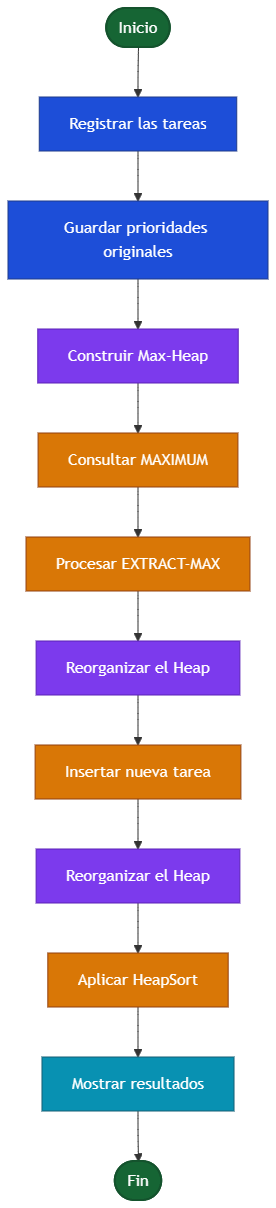


### 5) Análisis de complejidad **[15 pts]**

Se toma n como la cantidad de tareas o elementos del arreglo.

**Justificación**

El Max-Heap se guarda en un arreglo. Para encontrar los hijos de una posición solo se hacen operaciones de índices. La altura del árbol es aproximadamente log₂(n), por eso subir o bajar un elemento puede recorrer como máximo esa cantidad de niveles.

**Función T[n] y complejidades**


MAXIMUM:	Mejor caso: O(1)  Peor caso:	O(1)

MAX-HEAPIFY Mejor caso:	O(1) Peor caso:	O(log n)

BUILD-MAX-HEAP Mejor caso:	O(n) Peor caso:	O(n)

EXTRACT-MAX	Mejor caso: O(1) Peor caso: 	O(log n)

INSERT Mejor caso:	O(1) Peor caso:	O(log n)

HEAPSORT Mejor caso:	O(n log n) Peor caso:	O(n log n)



**Gráfica aproximada de crecimiento**

La gráfica compara el crecimiento de n y n log₂(n). Se observa que HeapSort crece más rápido que una operación lineal, pero mucho menos que una cuadrática.

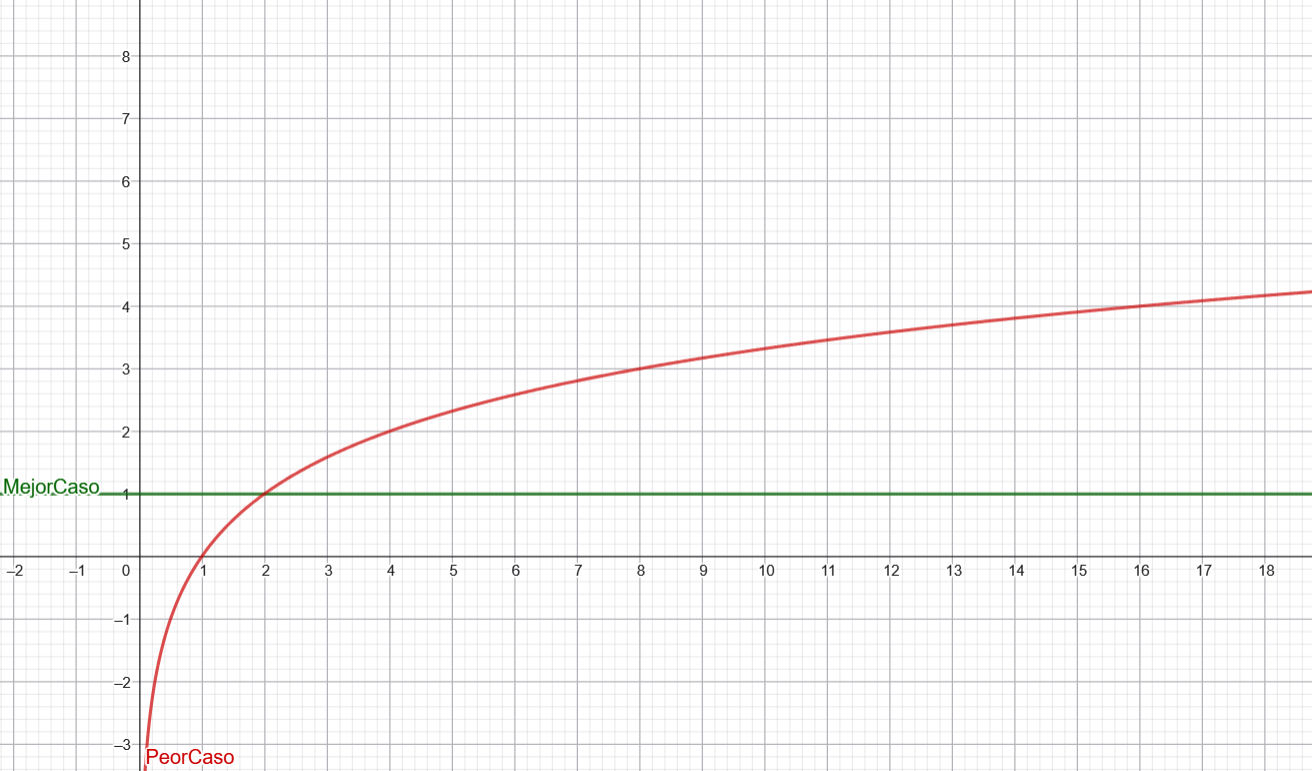

## 6) Código funcional **[15 pts]**

Se implementan las funciones del laboratorio. El arreglo guarda diccionarios con los datos de cada tarea. Para la ejecución visible se usan seis tareas de prueba; también queda la función para registrar tareas por teclado.


In [2]:
# Registrar tareas por teclado
def registrar_tareas():
    tareas = []
    n = int(input("Cantidad de tareas: "))

    for i in range(n):
        print("\nTarea", i + 1)
        codigo = input("Código: ")
        nombre = input("Nombre: ")
        prioridad = int(input("Prioridad: "))

        tarea = {
            "codigo": codigo,
            "nombre": nombre,
            "prioridad": prioridad
        }
        tareas.append(tarea)

    return tareas


# MAX-HEAPIFY
def max_heapify(heap, n, i):
    mayor = i
    izquierdo = 2 * i + 1
    derecho = 2 * i + 2

    if izquierdo < n and heap[izquierdo]["prioridad"] > heap[mayor]["prioridad"]:
        mayor = izquierdo

    if derecho < n and heap[derecho]["prioridad"] > heap[mayor]["prioridad"]:
        mayor = derecho

    if mayor != i:
        heap[i], heap[mayor] = heap[mayor], heap[i]
        max_heapify(heap, n, mayor)


# BUILD-MAX-HEAP
def build_max_heap(heap):
    n = len(heap)

    for i in range(n // 2 - 1, -1, -1):
        max_heapify(heap, n, i)


# MAXIMUM
def maximum(heap):
    if len(heap) == 0:
        return None
    return heap[0]


# EXTRACT-MAX
def extract_max(heap):
    if len(heap) == 0:
        return None

    mayor = heap[0]
    ultimo = heap.pop()

    if len(heap) > 0:
        heap[0] = ultimo
        max_heapify(heap, len(heap), 0)

    return mayor


# INSERT
def insertar(heap, nueva_tarea):
    heap.append(nueva_tarea.copy())
    i = len(heap) - 1

    while i > 0:
        padre = (i - 1) // 2

        if heap[padre]["prioridad"] >= heap[i]["prioridad"]:
            break

        heap[padre], heap[i] = heap[i], heap[padre]
        i = padre


# MAX-HEAPIFY para números, usado en HeapSort
def max_heapify_numeros(lista, n, i):
    mayor = i
    izquierdo = 2 * i + 1
    derecho = 2 * i + 2

    if izquierdo < n and lista[izquierdo] > lista[mayor]:
        mayor = izquierdo

    if derecho < n and lista[derecho] > lista[mayor]:
        mayor = derecho

    if mayor != i:
        lista[i], lista[mayor] = lista[mayor], lista[i]
        max_heapify_numeros(lista, n, mayor)


# HEAPSORT
def heapsort(lista):
    arreglo = lista.copy()
    n = len(arreglo)

    for i in range(n // 2 - 1, -1, -1):
        max_heapify_numeros(arreglo, n, i)

    for i in range(n - 1, 0, -1):
        arreglo[0], arreglo[i] = arreglo[i], arreglo[0]
        max_heapify_numeros(arreglo, i, 0)

    return arreglo


def mostrar_heap(heap):
    return [tarea["prioridad"] for tarea in heap]


# Prueba con seis tareas
tareas = [
    {"codigo": "T01", "nombre": "Compilar proyecto", "prioridad": 8},
    {"codigo": "T02", "nombre": "Generar backup", "prioridad": 4},
    {"codigo": "T03", "nombre": "Renderizar video", "prioridad": 10},
    {"codigo": "T04", "nombre": "Procesar correos", "prioridad": 3},
    {"codigo": "T05", "nombre": "Ejecutar pruebas", "prioridad": 7},
    {"codigo": "T06", "nombre": "Actualizar base de datos", "prioridad": 6}
]

prioridades_originales = [t["prioridad"] for t in tareas]

print("1. REGISTRO DE TAREAS")
for tarea in tareas:
    print(tarea["codigo"], "-", tarea["nombre"], "- Prioridad:", tarea["prioridad"])
print("Lista original de prioridades:", prioridades_originales)

# Se hace una copia para conservar las tareas originales.
heap = [t.copy() for t in tareas]
build_max_heap(heap)

print("\n2. CONSTRUCCIÓN DEL MAX-HEAP")
print("Lista original:", prioridades_originales)
print("Max-Heap:", mostrar_heap(heap))
print("Árbol por niveles:")
inicio = 0
nivel = 0
while inicio < len(heap):
    fin = min(inicio + 2 ** nivel, len(heap))
    print("Nivel", nivel, ":", mostrar_heap(heap[inicio:fin]))
    inicio = fin
    nivel += 1

print("\n3. COLA DE PRIORIDAD")

# Consultar la tarea de mayor prioridad
tarea_mayor = maximum(heap)
print("A. Tarea de mayor prioridad:")
print(tarea_mayor["codigo"], "-", tarea_mayor["nombre"],
      "Prioridad:", tarea_mayor["prioridad"])

# Procesar la tarea de mayor prioridad
procesada = extract_max(heap)
print("\nB. Tarea procesada:")
print(procesada["codigo"], "-", procesada["nombre"],
      "Prioridad:", procesada["prioridad"])
print("Nuevo Heap:", mostrar_heap(heap))

# Insertar una tarea nueva
nueva_tarea = {
    "codigo": "T07",
    "nombre": "Actualizar servidor",
    "prioridad": 12
}
insertar(heap, nueva_tarea)

print("\nC. Tarea insertada:")
print(nueva_tarea["codigo"], "-", nueva_tarea["nombre"],
      "Prioridad:", nueva_tarea["prioridad"])
print("Heap después de insertar:", mostrar_heap(heap))

print("\n4. HEAPSORT")
heap_original = prioridades_originales.copy()
for i in range(len(heap_original) // 2 - 1, -1, -1):
    max_heapify_numeros(heap_original, len(heap_original), i)

print("Lista original:", prioridades_originales)
print("Max-Heap:", heap_original)
print("Lista ordenada:", heapsort(prioridades_originales))


1. REGISTRO DE TAREAS
T01 - Compilar proyecto - Prioridad: 8
T02 - Generar backup - Prioridad: 4
T03 - Renderizar video - Prioridad: 10
T04 - Procesar correos - Prioridad: 3
T05 - Ejecutar pruebas - Prioridad: 7
T06 - Actualizar base de datos - Prioridad: 6
Lista original de prioridades: [8, 4, 10, 3, 7, 6]

2. CONSTRUCCIÓN DEL MAX-HEAP
Lista original: [8, 4, 10, 3, 7, 6]
Max-Heap: [10, 7, 8, 3, 4, 6]
Árbol por niveles:
Nivel 0 : [10]
Nivel 1 : [7, 8]
Nivel 2 : [3, 4, 6]

3. COLA DE PRIORIDAD
A. Tarea de mayor prioridad:
T03 - Renderizar video Prioridad: 10

B. Tarea procesada:
T03 - Renderizar video Prioridad: 10
Nuevo Heap: [8, 7, 6, 3, 4]

C. Tarea insertada:
T07 - Actualizar servidor Prioridad: 12
Heap después de insertar: [12, 7, 8, 3, 4, 6]

4. HEAPSORT
Lista original: [8, 4, 10, 3, 7, 6]
Max-Heap: [10, 7, 8, 3, 4, 6]
Lista ordenada: [3, 4, 6, 7, 8, 10]


## 7) Tests aplicados **[15 pts]**

Se prueban las operaciones principales con `assert`: que el Max-Heap quede bien construido, que `MAXIMUM` consulte el valor correcto, que `EXTRACT-MAX` retire el máximo, que la inserción mantenga la propiedad y que HeapSort ordene correctamente.


In [3]:
# Comprobar la propiedad del Max-Heap
def es_max_heap(heap):
    for i in range(len(heap) // 2):
        izquierdo = 2 * i + 1
        derecho = 2 * i + 2

        if izquierdo < len(heap):
            assert heap[i]["prioridad"] >= heap[izquierdo]["prioridad"]

        if derecho < len(heap):
            assert heap[i]["prioridad"] >= heap[derecho]["prioridad"]

    return True


# Pruebas con los datos de la ejecución
heap_prueba = [t.copy() for t in tareas]
build_max_heap(heap_prueba)

assert es_max_heap(heap_prueba)
assert maximum(heap_prueba)["prioridad"] == 10

extraida_prueba = extract_max(heap_prueba)
assert extraida_prueba["prioridad"] == 10
assert es_max_heap(heap_prueba)

insertar(heap_prueba, {
    "codigo": "T08",
    "nombre": "Revisar sistema",
    "prioridad": 15
})
assert maximum(heap_prueba)["prioridad"] == 15
assert es_max_heap(heap_prueba)

assert heapsort(prioridades_originales) == [3, 4, 6, 7, 8, 10]
assert heapsort([]) == []
assert heapsort([5]) == [5]

print("Todas las pruebas pasaron correctamente.")


Todas las pruebas pasaron correctamente.
